# GeoSPSR Comparison

## Imports

In [10]:
from functools import partial
import numpy as np
import jax.numpy as jnp
from jax import vmap, random

from geospsr.kernels import Matern32Kernel, ProductKernel
from geospsr.utils import trunc_Zd, periodic_stationary_interpolator
from geospsr.gp import (poisson_cross_covariances, compute_mean,
                        f_eigenvalues_from_v_eigenvalues)

from skimage.measure import marching_cubes
import open3d as o3d
from pyprojroot import here
from huggingface_hub import snapshot_download

## Download point cloud data

In [11]:
DATA_DIR = here("data/ppsurf")

# https://huggingface.co/datasets/perler/ppsurf
if not (DATA_DIR / "famous_noisefree").exists():
    snapshot_download(
        "perler/ppsurf",
        repo_type="dataset",
        allow_patterns=["famous_*/*"],
        local_dir=DATA_DIR
    )

## Functions

In [12]:
VARIANTS = ["famous_noisefree", "famous_original", "famous_sparse",
            "famous_dense", "famous_extra_noisy"]
SHAPES = ["xyzrgb_statuette"]

def load_points(variant: str, shape: str) -> np.ndarray:
    path = DATA_DIR / variant / "04_pts_vis" / f"{shape}.xyz.ply"
    return np.asarray(o3d.io.read_point_cloud(str(path)).points)

def estimate_normals(points: np.ndarray, knn_k=50, orient_k=30) -> np.ndarray:
    pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points))
    pcd.estimate_normals(o3d.geometry.KDTreeSearchParamKNN(knn_k))
    pcd.orient_normals_consistent_tangent_plane(orient_k)
    center = np.mean(points, axis=0)
    normals = np.asarray(pcd.normals)
    
    dots = np.sum((points - center) * normals, axis=1)
    if np.mean(dots > 0) < 0.5:
        normals = -normals
    return normals

def normalize_points(v):
    lo, hi = v.min(0), v.max(0)
    center = (lo + hi) / 2
    scale = (hi - lo).max()
    return (v - center) / scale, center, scale

def denormalize_points(v, center, scale):
    return v * scale + center

def get_gt_pcd(variant: str, shape: str, N: int) -> o3d.geometry.PointCloud:
    path = DATA_DIR / variant / "03_meshes" / f"{shape}.ply"
    gt_mesh = o3d.io.read_triangle_mesh(str(path))
    gt_mesh.compute_triangle_normals()
    gt_mesh.compute_vertex_normals()
    gt_pcd = gt_mesh.sample_points_uniformly(N, True)
    return gt_pcd


## Kernel boilerplate

In [13]:
sigma = 0.02
lengthscale = 1e-2
variance = 0.1
truncation_n = 50
amortization_density = 50

k = Matern32Kernel(lengthscale, variance)
k_v = ProductKernel(k, k, k)

k_v_eigenvectors = trunc_Zd(truncation_n)
k_v_eigenvalues = vmap(k_v.spectral_density)(k_v_eigenvectors) ** 0.5

k_fv_expensive = partial(
    poisson_cross_covariances,
    eigenvectors=k_v_eigenvectors,
    eigenvalues=k_v_eigenvalues,
)
k_fv = periodic_stationary_interpolator(
    k_fv_expensive, 3, amortization_density, exponent=5, verbose=True
)

k_f_eigenvalues = f_eigenvalues_from_v_eigenvalues(
    k_v_eigenvectors, k_v_eigenvalues)
k_f_variance = (k_f_eigenvalues**2).sum()



Creating interpolator:   0%|          | 0/977 [00:00<?, ?it/s]

## Reconstruction

In [15]:
OUT_DIR = here("data/results/comparison")
OUT_DIR.mkdir(parents=True, exist_ok=True)


def sdd_params_for(n_points, bs=128):
    """
    SDD settings that converge for this kernel (variance 0.1 per axis, ls 0.01).
    The stochastic gradient is scaled by N/bs, so the stable lr shrinks ~1/N;
    40 epochs gave residual < 1e-3 and alpha within 0.2% of Cholesky on all 5 variants.
    """
    return {"key": random.key(0), "bs": bs, "lr": 6000 / n_points,
            "iterations": int(np.ceil(40 * n_points / bs))}


def geospsr_mesh(x_data, v_data, lin, center, scale, sdd_params=None):
    """GeoSPSR mean surface -> mesh in dataset coords; sdd_params=None -> Cholesky"""
    res = len(lin)
    X, Y, Z = np.meshgrid(lin, lin, lin, indexing="ij")
    x_grid = np.stack([X, Y, Z], -1).reshape(-1, 3)

    # Concatenated grid points and data points
    # to avoid calling compute_mean function twice.
    query = jnp.concatenate([x_data, x_grid])
    mean = compute_mean(
        query, x_data, v_data, k_v, k_fv, sigma,
        bs=int(np.clip(2**30 // (len(x_data) * 120), 32, 4096)),
        sdd_params=sdd_params, verbose=True
    )

    iso = mean[:len(x_data)].mean()
    vol = np.array(mean[len(x_data):]).reshape(res, res, res)
    step = lin[1] - lin[0]
    verts, faces, _, _ = marching_cubes(vol, iso, spacing=(step, step, step))
    verts = verts + lin[0]
    verts = denormalize_points(verts / np.pi, center, scale)

    return o3d.geometry.TriangleMesh(
        o3d.utility.Vector3dVector(verts),
        o3d.utility.Vector3iVector(faces)
    )
    
def screened_psr_mesh(p: np.ndarray) -> o3d.geometry.TriangleMesh:
    pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(p))
    pcd.normals = o3d.utility.Vector3dVector(estimate_normals(p))
    mesh, densities = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
        pcd, depth=8)
    return mesh

def delaunay_alpha_shape_mesh(p: np.ndarray) -> o3d.geometry.TriangleMesh:
    pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(p))
    tetra_mesh, pt_map = o3d.geometry.TetraMesh.create_from_point_cloud(pcd)
    mesh = o3d.geometry.TriangleMesh.create_from_point_cloud_alpha_shape(
        pcd, 0.03, tetra_mesh, pt_map)
    mesh.compute_vertex_normals()
    return mesh

for variant in VARIANTS:
    for shape in SHAPES:

        res = 64
        half = np.pi / 2 * 1.1
        lin = np.linspace(-half, half, res)

        p = load_points(variant, shape)
        p, center, scale = normalize_points(p)
        p = p * np.pi
        n = estimate_normals(p)

        x_data = jnp.array(p)
        v_data = jnp.array(n)

        for solver, sdd_params in [("cholesky", None),
                                   ("sdd", sdd_params_for(len(x_data)))]:
            path = OUT_DIR / f"{shape}_{variant}_geospsr_{solver}.ply"
            if not path.exists():
                mesh = geospsr_mesh(x_data, v_data, lin, center, scale, sdd_params)
                o3d.io.write_triangle_mesh(str(path), mesh)

        p = load_points(variant, shape)
        path = OUT_DIR / f"{shape}_{variant}_screened_psr.ply"    
        if not path.exists():
            mesh = screened_psr_mesh(p)
            o3d.io.write_triangle_mesh(str(path), mesh)
            
        path = OUT_DIR / f"{shape}_{variant}_delaunay_alpha_shape.ply"
        if not path.exists():
            mesh = delaunay_alpha_shape_mesh(p)
            o3d.io.write_triangle_mesh(str(path), mesh)
            

## Visualization

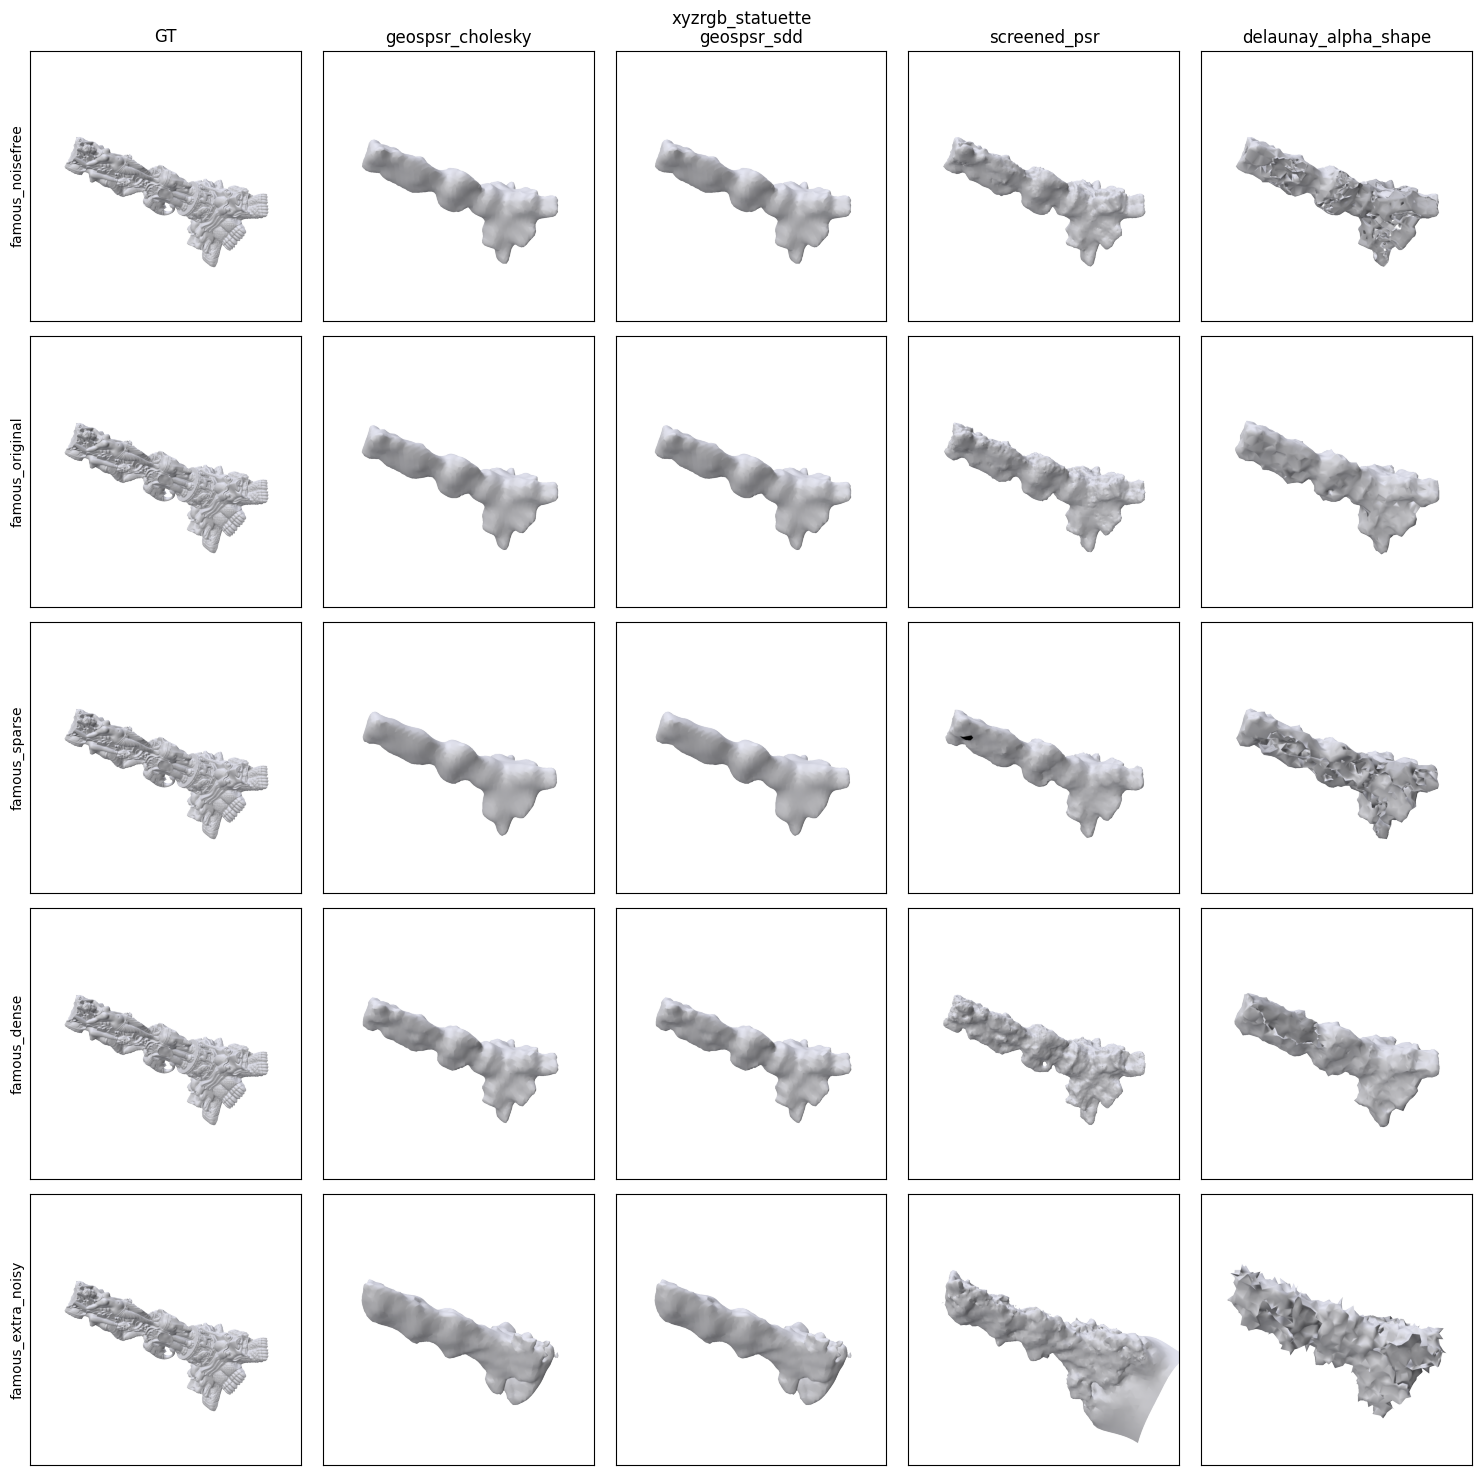

In [16]:
import polyscope as ps
import matplotlib.pyplot as plt

METHODS = ["GT", "geospsr_cholesky", "geospsr_sdd", "screened_psr",
           "delaunay_alpha_shape"]

ps.init()
ps.set_up_dir("z_up")

ps.set_ground_plane_mode("none")
ps.set_window_size(1200, 1200)

imgs = {}
for variant in VARIANTS:
    for shape in SHAPES:
        for method in METHODS:
            if method == "GT":
                path = DATA_DIR / variant / "03_meshes" / f"{shape}.ply"
            else:
                path = OUT_DIR / f"{shape}_{variant}_{method}.ply"
            
            mesh = o3d.io.read_triangle_mesh(str(path))
            ps.remove_all_structures()
            ps.register_surface_mesh(
                f"{shape} | {variant} | {method}",
                np.asarray(mesh.vertices),
                np.asarray(mesh.triangles), smooth_shade=True,
                color=(0.75, 0.75, 0.78))
            ps.look_at(camera_location=(1.0, -1.0, 1.0),
                       target=(0.0, 0.0, 0.0))
            imgs[(shape, variant, method)] = ps.screenshot_to_buffer(True)
                 
for shape in SHAPES:
    nr, nc = len(VARIANTS), len(METHODS)
    fig, axes = plt.subplots(nr, nc,
                             figsize=(3 * nc, 3 * nr), 
                             squeeze=False)

    for i, variant in enumerate(VARIANTS):
        for j, method in enumerate(METHODS):
            ax = axes[i, j]
            key = (shape, variant, method)
            ax.imshow(imgs[key])
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set
            if i == 0: 
                ax.set_title(method)
            if j == 0:
                ax.set_ylabel(variant)
    fig.suptitle(shape)
    plt.tight_layout()
    plt.show()